In [1]:
#Example of supress warnings for Numpy version out of range (optional)
import warnings
warnings.filterwarnings("ignore", category=Warning)

#Pull in the libraries we need
import pandas as pd
from sklearn.datasets import load_digits

#New libraries for access to model selection tasks
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

#Pull in the plotting library and specify to display inline/static images
import matplotlib.pyplot as plt
%matplotlib inline

#and graphviz for visualization
from sklearn import tree
from sklearn.tree import export_graphviz
import graphviz

In [2]:
#First step is to load the data into an oject and setup our X and y
digitsRaw = load_digits()
#print(digitsRaw.DESCR)

#This is an example you can use for preprocessing and beyond if you would like vs. using a DataFrame
X = digitsRaw.data
y = digitsRaw.target

#X = pd.DataFrame(digitsRaw.data, columns=digitsRaw.feature_names)
#y = pd.Series(digitsRaw.target)
#X.head()

#Using the shape command, you can investigate the dimensionality
print('Shape of Data (X):',digitsRaw.data.shape)
print('Shape of Target Data (y)', digitsRaw.target.shape)

#We have 1797 data samples, observations, or images each 8x8 in size
print('Shape of the images', digitsRaw.images.shape, '\n')

Shape of Data (X): (1797, 64)
Shape of Target Data (y) (1797,)
Shape of the images (1797, 8, 8) 



In [4]:
#Split the dataset into training and testing sets with 80% training and 20% testing
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [5]:
#Initialize the DT classifier model object and train (or fit) the data
#Note, we set random_state to a fixed integer to obtain a consistent result
#Other params: max_depth controls the depth of the tree (default is None) 
#min_samples_split controls minimum number of samples required to split (default is 2)
#min_samples_leaf controls the minimum number of samples required to be at a leaf node (default is 1)
clf_dt = DecisionTreeClassifier(random_state=42, 
                                criterion = 'gini',
                                max_depth=5, 
                                min_samples_split=10, 
                                min_samples_leaf=5)
clf_dt.fit(X_train, y_train)

DecisionTreeClassifier(max_depth=5, min_samples_leaf=5, min_samples_split=10,
                       random_state=42)

In [6]:
#Make predictions
y_pred_dt = clf_dt.predict(X_test)

#Evaluate the classifier
print("Decision Tree Performance:")
print(f"Accuracy: {accuracy_score(y_test, y_pred_dt)}", '\n')
print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred_dt))
print("Classification Report:")
print(classification_report(y_test, y_pred_dt))

Decision Tree Performance:
Accuracy: 0.675 

Confusion Matrix:
[[30  0  0  0  1  1  0  0  1  0]
 [ 0  7  1  2  3  0  0  0 15  0]
 [ 0  0  7  1  1  0  1  1 22  0]
 [ 0  2  1 28  0  0  0  0  3  0]
 [ 0  2  1  0 39  0  0  1  3  0]
 [ 0  1  0  1  1 44  0  0  0  0]
 [ 0  1  0  0  1  1 32  0  0  0]
 [ 0  2  1  2  2  0  0 22  5  0]
 [ 0  0  0  8  0  0  0  0 22  0]
 [ 0  1  0 25  2  0  0  0  0 12]]
Classification Report:
              precision    recall  f1-score   support

           0       1.00      0.91      0.95        33
           1       0.44      0.25      0.32        28
           2       0.64      0.21      0.32        33
           3       0.42      0.82      0.55        34
           4       0.78      0.85      0.81        46
           5       0.96      0.94      0.95        47
           6       0.97      0.91      0.94        35
           7       0.92      0.65      0.76        34
           8       0.31      0.73      0.44        30
           9       1.00      0.30      0.4

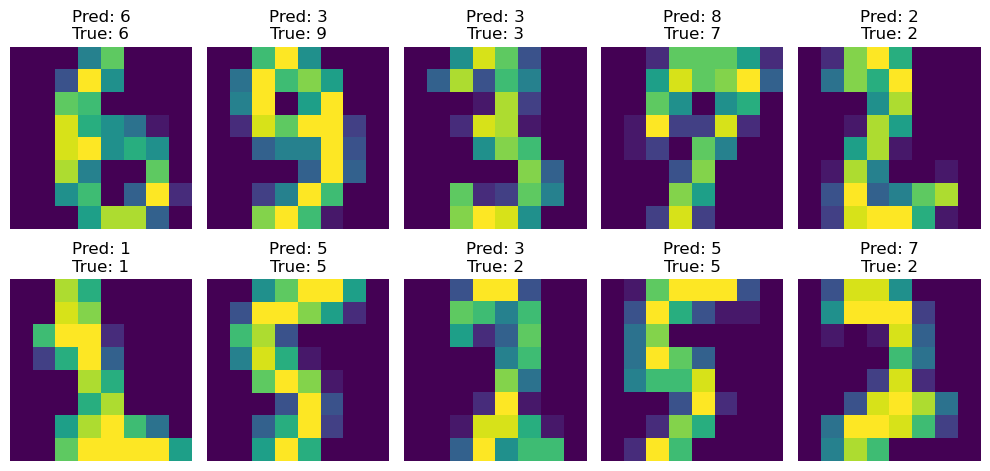

In [7]:
#Plot a few sample images along with their predictions for our Decision Tree
fig, axes = plt.subplots(2, 5, figsize=(10, 5))
for ax, image, prediction, label in zip(axes.flatten(), X_test, y_pred_dt, y_test):
    ax.imshow(image.reshape(8, 8))#, cmap='gray')
    ax.set_title(f'Pred: {prediction}\nTrue: {label}')
    ax.axis('off')

plt.tight_layout()
plt.show()

## Random Forest

In [9]:
from sklearn.ensemble import RandomForestClassifier

In [12]:
#Initialize the RF classifier model object and train (or fit) the data
#Note, we set random_state to a fixed integer to obtain a consistent result
clf_rf = RandomForestClassifier(n_estimators=100, random_state=42)
clf_rf.fit(X_train, y_train)

#Make predictions
y_pred_rf = clf_rf.predict(X_test)

#Evaluate the classifier
print("\nRandom Forest Performance:")
print(f"Accuracy: {accuracy_score(y_test, y_pred_rf)}", '\n')
print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred_rf))
print("Classification Report:")
print(classification_report(y_test, y_pred_rf))


Random Forest Performance:
Accuracy: 0.9722222222222222 

Confusion Matrix:
[[32  0  0  0  1  0  0  0  0  0]
 [ 0 28  0  0  0  0  0  0  0  0]
 [ 0  0 33  0  0  0  0  0  0  0]
 [ 0  0  0 32  0  1  0  0  1  0]
 [ 0  0  0  0 46  0  0  0  0  0]
 [ 0  0  0  0  0 45  1  0  0  1]
 [ 0  0  0  0  0  1 34  0  0  0]
 [ 0  0  0  0  0  0  0 33  0  1]
 [ 0  1  0  0  0  0  0  0 29  0]
 [ 0  0  0  0  0  1  0  1  0 38]]
Classification Report:
              precision    recall  f1-score   support

           0       1.00      0.97      0.98        33
           1       0.97      1.00      0.98        28
           2       1.00      1.00      1.00        33
           3       1.00      0.94      0.97        34
           4       0.98      1.00      0.99        46
           5       0.94      0.96      0.95        47
           6       0.97      0.97      0.97        35
           7       0.97      0.97      0.97        34
           8       0.97      0.97      0.97        30
           9       0.95     

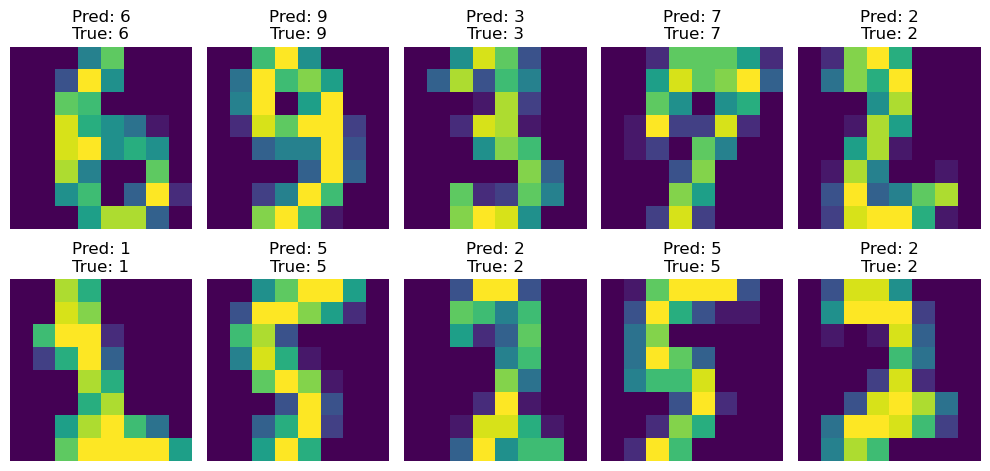

In [13]:
#Plot a few sample images along with their predictions for our Random Forest
fig, axes = plt.subplots(2, 5, figsize=(10, 5))
for ax, image, prediction, label in zip(axes.flatten(), X_test, y_pred_rf, y_test):
    ax.imshow(image.reshape(8, 8))#, cmap='gray')
    ax.set_title(f'Pred: {prediction}\nTrue: {label}')
    ax.axis('off')

plt.tight_layout()
plt.show()